# IND320 - Project Work Part 2

**Name:** Yamama Alhalabi

**GitHub repository:** https://github.com/yamamaalhalabi/ind320-yamamaalhalabi

**Streamlit app:** https://ind320-yamamaalhalabi.streamlit.app/

**Screencast:** (add the Panopto link here, with sharing set to "anyone")

In [1]:
import pandas as pd
import requests

BASE = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk"

# Download the full weekly history for all areas directly from NVE's API.
# This replaces the reservoirs.csv file from part 1, so the data is always
# current and the repository no longer needs to store a data file.
resp = requests.get(f"{BASE}/HentOffentligData", timeout=30)
resp.raise_for_status()
df_all = pd.DataFrame(resp.json())

# The API returns dates as text, so convert them explicitly
df_all["dato_Id"] = pd.to_datetime(df_all["dato_Id"])

# Keep only the national level, as in part 1
df = df_all[df_all["omrType"] == "NO"].copy().sort_values("dato_Id")

# Rename columns to English, understandable names
df = df.rename(columns={
    "dato_Id": "date",
    "fyllingsgrad": "fill_ratio",
    "kapasitet_TWh": "capacity_twh",
    "fylling_TWh": "fill_twh",
    "fyllingsgrad_forrige_uke": "fill_ratio_prev_week",
    "endring_fyllingsgrad": "fill_ratio_change",
})

# Use the date as index and keep only the numeric columns
df = df.set_index("date")
df = df[["fill_ratio", "capacity_twh", "fill_twh",
         "fill_ratio_prev_week", "fill_ratio_change"]]

df.head()


,fill_ratio,capacity_twh,fill_twh,fill_ratio_prev_week,fill_ratio_change
date,,,,,
1995-01-08,0.607988,87.43758,53.161003,0.752631,-0.144643
1995-01-15,0.582088,87.43758,50.896374,0.607988,-0.025900
1995-01-22,0.562121,87.43758,49.150486,0.582088,-0.019967
1995-01-29,0.534222,87.43758,46.711033,0.562121,-0.027899
1995-02-05,0.506221,87.43758,44.262720,0.534222,-0.028001


In [2]:
# Which areas does each omrType cover?
df_all.groupby("omrType")["omrnr"].unique()

omrType
EL      [4, 1, 3, 5, 2]
NO                  [0]
VASS          [2, 3, 1]
Name: omrnr, dtype: object

In [3]:
# Fetch the lookup table of areas (country, price areas, watercourses).
# We use the same BASE url as for the reservoir data above.
resp_areas = requests.get(f"{BASE}/HentOmråder", timeout=30)
resp_areas.raise_for_status()
areas = resp_areas.json()

# Quick look at the structure before we unpack it
print(type(areas), len(areas))

<class 'list'> 1


In [4]:
# The response is a list with one dict inside; take the first element
areas_dict = areas[0]

# Combine country, price areas and watercourses into one table
areas_df = pd.DataFrame(areas_dict["land"] + areas_dict["elspot"] + areas_dict["vassdrag"])
areas_df[["omrType", "omrnr", "navn", "navn_langt"]]

,omrType,omrnr,navn,navn_langt
0,NO,0,Norge,Norge
1,EL,1,NO 1,Elspotområde 1
2,EL,2,NO 2,Elspotområde 2
3,EL,3,NO 3,Elspotområde 3
4,EL,4,NO 4,Elspotområde 4
5,EL,5,NO 5,Elspotområde 5
6,VASS,1,VASS1,Vassdragsområde 1
7,VASS,2,VASS2,Vassdragsområde 2
8,VASS,3,VASS3,Vassdragsområde 3
9,VASS,4,VASS4,Vassdragsområde 4


In [5]:
# Does the data contain every area that the lookup lists?
in_data = df_all[["omrType", "omrnr"]].drop_duplicates()
check = areas_df.merge(in_data, on=["omrType", "omrnr"], how="left", indicator=True)
check[["omrType", "omrnr", "navn", "_merge"]]

,omrType,omrnr,navn,_merge
0,NO,0,Norge,both
1,EL,1,NO 1,both
2,EL,2,NO 2,both
3,EL,3,NO 3,both
4,EL,4,NO 4,both
5,EL,5,NO 5,both
6,VASS,1,VASS1,both
7,VASS,2,VASS2,both
8,VASS,3,VASS3,both
9,VASS,4,VASS4,left_only


In [6]:
%pip install pymongo


[notice] A new release of pip available: 22.2.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
from pathlib import Path

# Show where the notebook is running and whether the secrets file exists
print("Working directory:", Path.cwd())
print("Exists here:", Path(".streamlit/secrets.toml").exists())
print("Exists one level up:", Path("../.streamlit/secrets.toml").exists())

In [12]:
from pathlib import Path
from pymongo import MongoClient

# Read the connection string from the local secrets file (never committed to GitHub).
# The notebook may run from the project root or from the notebooks folder,
# so we try both locations.
candidates = [Path(".streamlit/secrets.toml"), Path("../.streamlit/secrets.toml")]
secrets_path = next(p for p in candidates if p.exists())

uri = None
for line in secrets_path.read_text(encoding="utf-8").splitlines():
    if line.strip().startswith("uri"):
        # The value is the text between the quotation marks
        uri = line.split('"')[1]

# Basic sanity checks without printing the password
print("Length:", len(uri))
print("Starts correctly:", uri.startswith("mongodb+srv://"))
print("Placeholder left in string:", "<" in uri or ">" in uri)

StopIteration: 

In [10]:
# Connect to MongoDB Atlas using the string from the cell above
client = MongoClient(uri, serverSelectionTimeoutMS=10000)

# Test: write one document and read it back
test = client["ind320"]["connection_test"]
test.insert_one({"ok": True})
print(test.find_one())

InvalidURI: Invalid URI scheme: URI must begin with 'mongodb://' or 'mongodb+srv://'

In [ ]:
print(df.index[:3])
print(df.columns.tolist())

DatetimeIndex(['1995-01-08', '1995-01-15', '1995-01-22'], dtype='datetime64[ns]', name='date', freq=None)
['fill_ratio', 'capacity_twh', 'fill_twh', 'fill_ratio_prev_week', 'fill_ratio_change']


## Printing the contents

In [ ]:
# Basic overview of the dataset: size and covered period
print(f"Number of rows: {df.shape[0]}, number of columns: {df.shape[1]}")
print(f"Period: {df.index.min().date()} to {df.index.max().date()}")
df.describe()

Number of rows: 1658, number of columns: 5
Period: 1995-01-08 to 2026-10-11


,fill_ratio,capacity_twh,fill_twh,fill_ratio_prev_week,fill_ratio_change
count,1658.000000,1.658000e+03,1658.000000,1658.000000,1658.000000
mean,0.622169,8.743758e+01,54.400926,0.622206,-0.000037
std,0.195691,1.421514e-14,17.110790,0.195710,0.027673
min,0.180250,8.743758e+01,15.760602,0.180260,-0.144643
25%,0.461099,8.743758e+01,40.317419,0.461099,-0.022020
50%,0.647552,8.743758e+01,56.620398,0.647567,-0.005516
75%,0.788700,8.743758e+01,68.962040,0.788699,0.016301
max,0.966610,8.743758e+01,84.518060,0.966610,0.125774


## Plotting each column separately

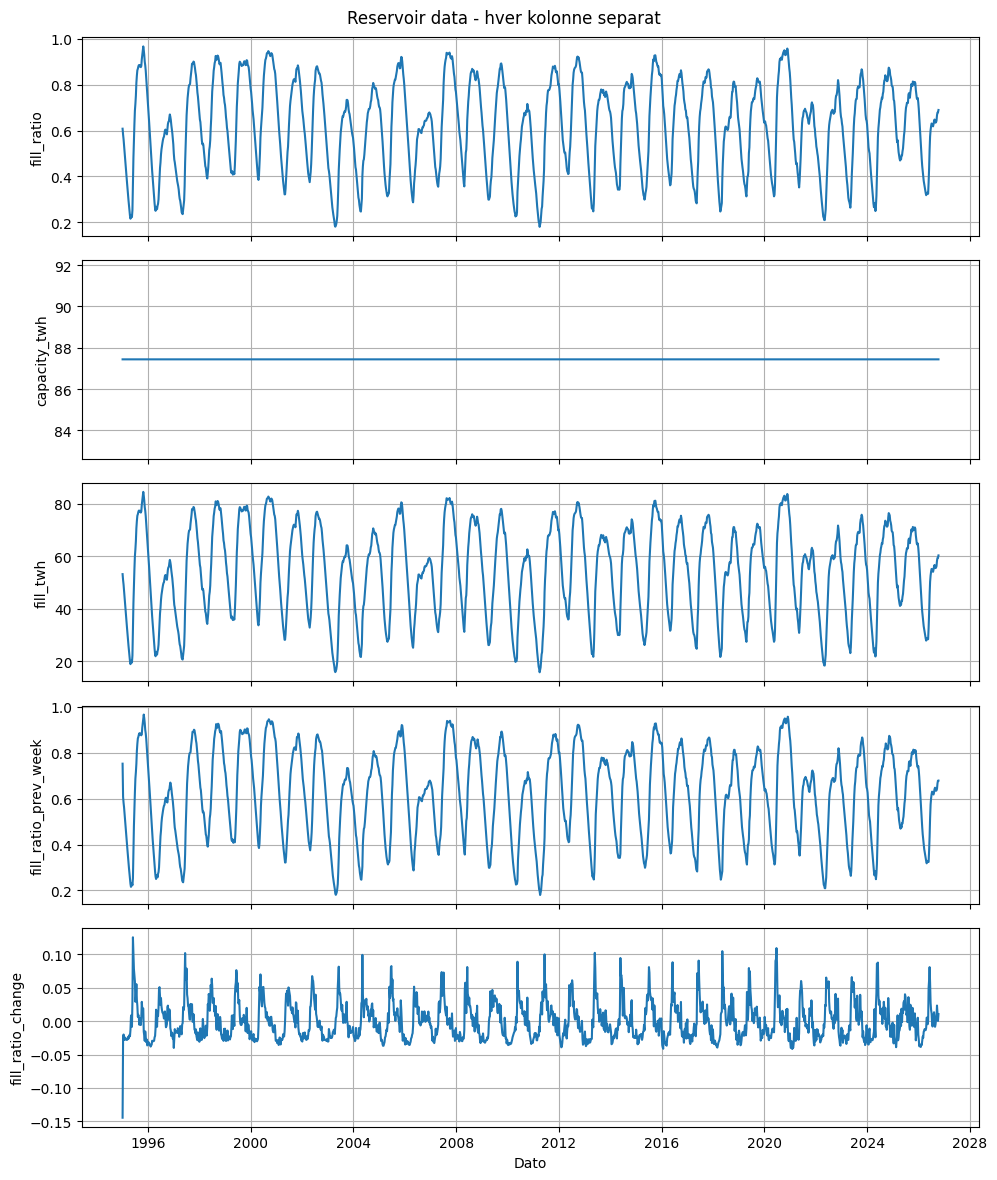

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(len(df.columns), 1, figsize=(10, 12), sharex=True)

for ax, col in zip(axes, df.columns):
    ax.plot(df.index, df[col])
    ax.set_ylabel(col)
    ax.grid(True)

axes[-1].set_xlabel("Dato")
fig.suptitle("Reservoir data - hver kolonne separat")
plt.tight_layout()
plt.show()

## Plotting all columns together

Since the columns have very different scales (e.g. `capacity_twh` is around 87, while `fill_ratio_change` is close to 0), each column is normalized to the same 0-1 scale before being shown in the same graph. This makes it possible to compare the patterns over time, even though the actual values differ greatly.

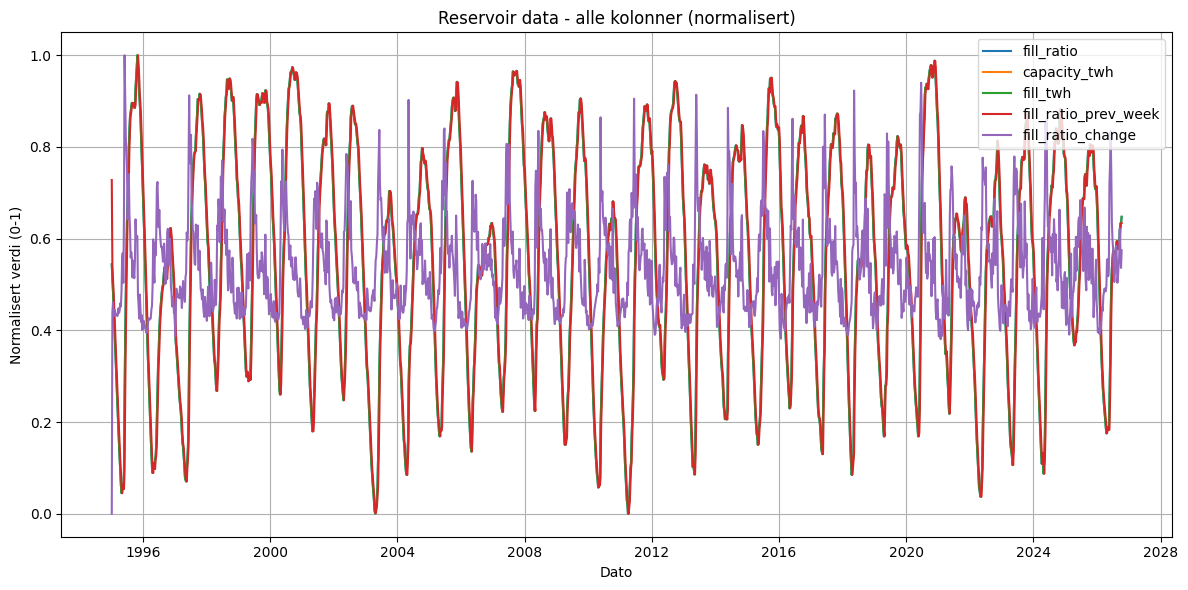

In [ ]:
# Normalize each column to a 0-1 scale so they can be compared
# despite having very different units and value ranges
df_normalized = (df - df.min()) / (df.max() - df.min())

fig, ax = plt.subplots(figsize=(12, 6))
for col in df_normalized.columns:
    ax.plot(df_normalized.index, df_normalized[col], label=col)

ax.set_xlabel("Dato")
ax.set_ylabel("Normalisert verdi (0-1)")
ax.set_title("Reservoir data - alle kolonner (normalisert)")
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

## Log

In this part of the project I replaced the CSV file from part 1 with a direct connection to the NVE Magasinstatistikk API. The notebook now downloads the full weekly history with requests, converts the date column explicitly (the API returns dates as text, which I remembered from part 1), filters the national level and renames the columns to English. The two plots from part 1 (each column separately, and all columns normalized) are recreated from the API data. I also looked at the area lookup endpoint and found that the data contains the national level (NO), five price areas (EL) and watercourse areas (VASS). One of the watercourse areas listed in the lookup (VASS4) has no data in the reservoir dataset.

I created a MongoDB Atlas account and tested the connection from Python with pymongo. My first attempts failed, first because the connection string had a placeholder left in it, and then because of an authentication error, which I solved by resetting the database user password. The connection string is entered with getpass in the notebook and stored in Streamlit secrets for the app, so no password is committed to GitHub.

In the Streamlit app, the table page and the plot page now fetch data from the NVE API (cached with st.cache_data) instead of reading a file. I added st.radio buttons to choose between area types (NO, EL, VASS), so that the table shows one row with a LineChartColumn per area number and the plot shows one line per area number. The slider on the plot page selects the time period that is shown. All work was done on a separate branch (part2) as required.

I created an ENTSO-E account and requested an API token on 20 October, but I had not received it at the time of the deadline. Because of this, the ENTSO-E data, the Cassandra/Spark part, the pie chart and the line plot page are not finished yet, and I will complete them when the token arrives.

## Use of AI

Claude (Anthropic) was used throughout the project to help with Python code (Pandas, Plotly, Streamlit), debugging error messages (including encoding issues in PowerShell), explaining Git/GitHub commands, and locating the correct source file (reservoirs.csv) in the course's GitHub repository.